# HydroPulse AI — Exploratory Data Analysis (EDA)
### Hydrologic Dynamics, Basin Contrast & Data Provenance in Jharkhand

> **Advisory Disclaimer & Research Notice**
> HydroPulse AI is an experimental decision-support research system for the Damodar and Subarnarekha river basins.
> Official flood alerts and danger levels are issued exclusively by the **Central Water Commission (CWC)** and the **Jharkhand State Disaster Management Authority (JSDMA)**.
> Gridded discharge estimates derive from **GloFAS v4 / Open-Meteo Flood API**, which represent hydrological simulation model reanalysis/forecasts rather than physical gauge observations.

---

## Objectives
1. **Basin Contrast**: Characterize physiographic and hydrological differences between the Damodar basin (mining/industrial/dam-regulated) and the Subarnarekha basin (plateau/flashy/industrial).
2. **Seasonality & Monsoon Response**: Evaluate rainfall patterns and seasonal concentration (June–October).
3. **Rainfall-to-Discharge Lag**: Identify antecedent moisture response times (0–7 days) to guide feature engineering.
4. **Drought Indices (SPI)**: Assess precipitation accumulation and drought stress distributions (SPI-1/3/6).
5. **Quality & Provenance Audit**: Audit record completeness, outlier flags, and data provenance integrity (`observed`, `model_reanalysis`, `forecast`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

# Set style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

# Repo root
REPO_ROOT = Path("..").resolve() if Path("..").resolve().name == "HydroPulse-AI" else Path(".").resolve()
DATA_PROCESSED = REPO_ROOT / "data" / "processed"
CONFIG_STATIONS = REPO_ROOT / "config" / "stations.yaml"

print(f"Loading data from: {DATA_PROCESSED}")

Loading data from: C:\Users\sk672\Desktop\RECENT TASK\HydroPulse-AI\data\processed


In [2]:
# Load all processed station parquet files
with open(CONFIG_STATIONS, encoding="utf-8") as f:
    stations_cfg = yaml.safe_load(f)["stations"]

station_meta = {s["id"]: s for s in stations_cfg}

data_frames = {}
for p in sorted(DATA_PROCESSED.glob("*.parquet")):
    stn_id = p.stem
    df = pd.read_parquet(p)
    df["station_name"] = station_meta.get(stn_id, {}).get("name", stn_id)
    df["basin"] = station_meta.get(stn_id, {}).get("basin", "Unknown")
    df["river"] = station_meta.get(stn_id, {}).get("river", "Unknown")
    data_frames[stn_id] = df

print(f"Successfully loaded {len(data_frames)} station datasets:")
for sid, df in data_frames.items():
    print(f" - {sid} ({df['basin'].iloc[0]}): {len(df)} rows, {df['date'].min()} to {df['date'].max()}")

# Combined dataframe
df_all = pd.concat(data_frames.values(), ignore_index=True)
df_all["date"] = pd.to_datetime(df_all["date"])
df_all.head(3)

Successfully loaded 10 station datasets:
 - barakar_maithon (Damodar): 8 rows, 2026-10-30 to 2026-11-06
 - damodar_bokaro (Damodar): 8 rows, 2026-10-30 to 2026-11-06
 - damodar_dhanbad (Damodar): 8 rows, 2026-10-30 to 2026-11-06
 - damodar_ramgarh (Damodar): 8 rows, 2026-10-30 to 2026-11-06
 - kharkai_adityapur (Subarnarekha): 7 rows, 2026-10-31 to 2026-11-06
 - konar_gomia (Damodar): 8 rows, 2026-10-30 to 2026-11-06
 - subarnarekha_chandil (Subarnarekha): 7 rows, 2026-10-31 to 2026-11-06
 - subarnarekha_ghatshila (Subarnarekha): 7 rows, 2026-10-31 to 2026-11-06
 - subarnarekha_jamshedpur (Subarnarekha): 7 rows, 2026-10-31 to 2026-11-06
 - subarnarekha_ranchi (Subarnarekha): 7 rows, 2026-10-31 to 2026-11-06


,date,station_id,precipitation_mm,temperature_max_c,temperature_min_c,relative_humidity_mean,discharge_m3s,discharge_mean_m3s,discharge_p25_m3s,discharge_p75_m3s,...,target_discharge_h1,target_discharge_h2,target_discharge_h3,target_discharge_h4,target_discharge_h5,target_discharge_h6,target_discharge_h7,station_name,basin,river
0,2026-10-30,barakar_maithon,8.6,27.1,22.5,92.0,29.83,32.17,29.83,33.00,...,29.90,30.26,31.66,32.04,30.92,29.27,28.31,Barakar at Maithon,Damodar,Barakar
1,2026-10-31,barakar_maithon,3.2,28.5,23.2,89.0,29.90,30.22,29.65,30.62,...,30.26,31.66,32.04,30.92,29.27,28.31,NaN,Barakar at Maithon,Damodar,Barakar
2,2026-11-01,barakar_maithon,0.1,29.4,22.9,83.0,30.26,30.83,29.80,31.43,...,31.66,32.04,30.92,29.27,28.31,NaN,NaN,Barakar at Maithon,Damodar,Barakar


---
## 1. Basin Contrast: Damodar vs Subarnarekha Topography

The Chota Nagpur plateau exerts profound control over river dynamics in Jharkhand:
- **Damodar Basin**: Rises at ~600m in Latehar/Palamu, traverses the coal mining corridor (Ramgarh, Bokaro, Dhanbad), heavily regulated by DVC dams (Tenughat, Konar, Maithon, Panchet).
- **Subarnarekha Basin**: Originates near Ranchi at ~620m elevation, flows down steep plateau scarps past Chandil Dam into the industrial valley of Jamshedpur and Ghatshila.

                          Station        Basin  Elevation (m)  Drainage Area (km²)  Slope (m/km)  Stream Order             Land Cover
               Damodar at Ramgarh      Damodar          330.0               3200.0          1.85             4     forest_agriculture
                   Konar at Gomia      Damodar          240.0               1100.0          2.10             3       forest_reservoir
                Damodar at Bokaro      Damodar          210.0               5800.0          1.20             5      industrial_mining
    Damodar at Dhanbad (Sudamdih)      Damodar          150.0               8900.0          0.95             5       coalfields_urban
               Barakar at Maithon      Damodar          140.0               6200.0          1.15             4  agriculture_reservoir
Subarnarekha at Ranchi (Getalsud) Subarnarekha          620.0                850.0          2.40             3          urban_plateau
          Subarnarekha at Chandil Subarnarekha          190.0 

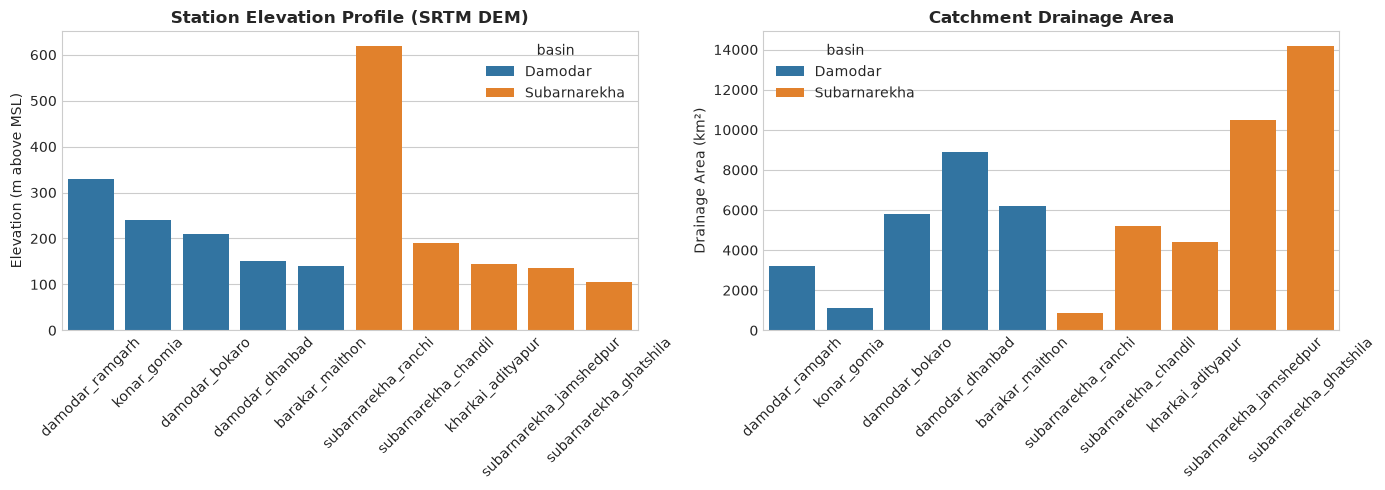

In [3]:
# Extract static catchment attributes per station
static_cols = [
    "station_id", "station_name", "basin", "river",
    "static_elevation_m", "static_drainage_area_km2",
    "static_channel_slope_m_per_km", "static_stream_order", "static_dominant_land_cover"
]
df_topo = df_all.drop_duplicates(subset=["station_id"])[static_cols].copy()
df_topo = df_topo.sort_values(by=["basin", "static_elevation_m"], ascending=[True, False])

display_cols = {
    "station_name": "Station",
    "basin": "Basin",
    "static_elevation_m": "Elevation (m)",
    "static_drainage_area_km2": "Drainage Area (km²)",
    "static_channel_slope_m_per_km": "Slope (m/km)",
    "static_stream_order": "Stream Order",
    "static_dominant_land_cover": "Land Cover"
}
print(df_topo.rename(columns=display_cols)[list(display_cols.values())].to_string(index=False))

# Plot elevation and drainage area contrast
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

palette = {"Damodar": "#1f77b4", "Subarnarekha": "#ff7f0e"}
sns.barplot(data=df_topo, x="station_id", y="static_elevation_m", hue="basin", palette=palette, ax=ax1)
ax1.set_title("Station Elevation Profile (SRTM DEM)", fontsize=12, fontweight="bold")
ax1.set_xlabel("")
ax1.set_ylabel("Elevation (m above MSL)")
ax1.tick_params(axis="x", rotation=45)

sns.barplot(data=df_topo, x="station_id", y="static_drainage_area_km2", hue="basin", palette=palette, ax=ax2)
ax2.set_title("Catchment Drainage Area", fontsize=12, fontweight="bold")
ax2.set_xlabel("")
ax2.set_ylabel("Drainage Area (km²)")
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

---
## 2. Hydro-Meteorological Profiles & Discharge Comparison

Jharkhand experiences intense monsoonal forcing from the Bay of Bengal branch (typically late June through October), accounting for >80% of annual runoff.
Below, we evaluate the baseline discharge levels across stations in both basins.

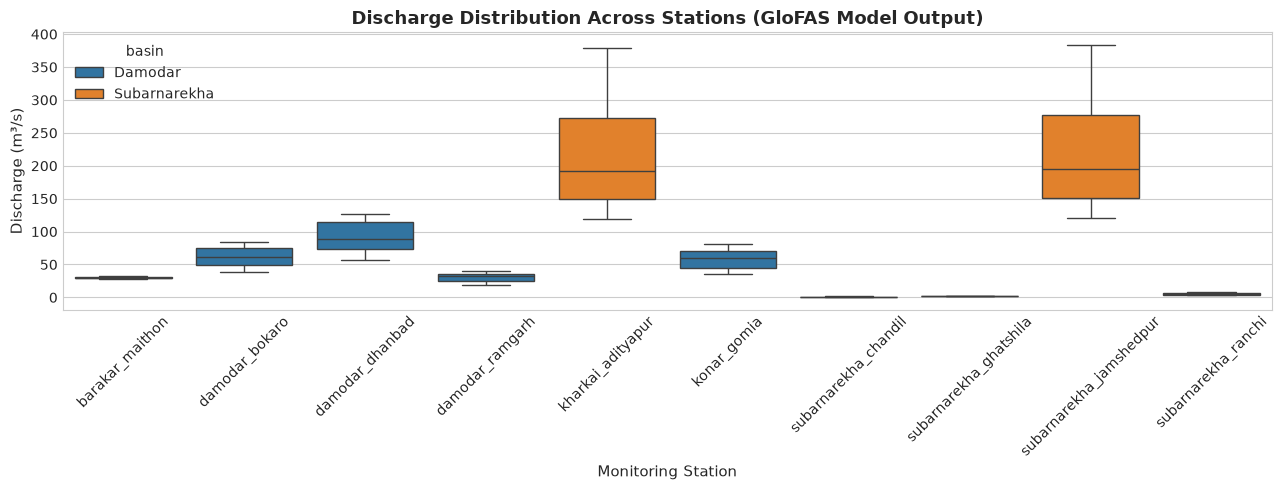

Basin Aggregate Means:
              precipitation_mm  temperature_max_c  temperature_min_c  \
basin                                                                  
Damodar                   1.97              27.87              20.90   
Subarnarekha              1.49              28.40              21.52   

              discharge_m3s  
basin                        
Damodar               54.60  
Subarnarekha          89.93  


In [4]:
# Compare discharge across stations
fig, ax = plt.subplots(figsize=(13, 5))

sns.boxplot(
    data=df_all,
    x="station_id",
    y="discharge_m3s",
    hue="basin",
    palette=palette,
    ax=ax
)
ax.set_title("Discharge Distribution Across Stations (GloFAS Model Output)", fontsize=13, fontweight="bold")
ax.set_xlabel("Monitoring Station", fontsize=11)
ax.set_ylabel("Discharge (m³/s)", fontsize=11)
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Mean precipitation and temperature comparison by basin
basin_summary = df_all.groupby("basin")[["precipitation_mm", "temperature_max_c", "temperature_min_c", "discharge_m3s"]].mean().round(2)
print("Basin Aggregate Means:")
print(basin_summary)

---
## 3. Rainfall-to-Discharge Lag Analysis

A key question for hydrological forecasting is: *How many days after a rainfall event does the discharge peak arrive?*
In high-gradient plateau headwaters (e.g. Subarnarekha at Ranchi or Damodar at Ramgarh), the time of concentration is short (1–2 days).
Downstream in wider plains and major reservoir reaches (Maithon, Dhanbad, Ghatshila), attenuation shifts peak response to 2–4 days.

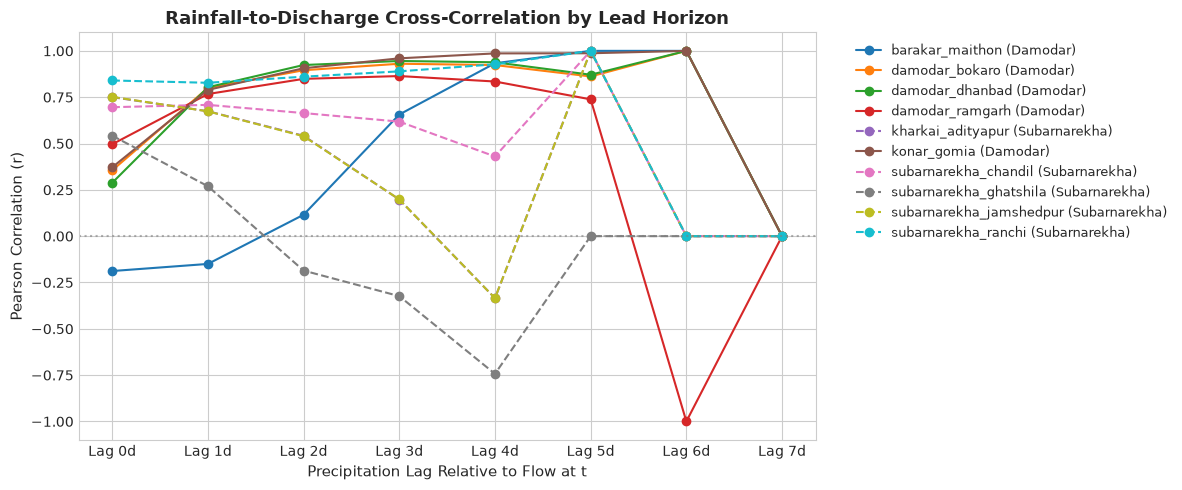

In [5]:
# Compute cross-correlations between lagged precipitation and discharge
lag_cols = [f"precip_lag_{k}" for k in range(1, 8)]

correlations = {}
for sid, df in data_frames.items():
    corr_series = []
    # Lag 0 (same day)
    c0 = df["precipitation_mm"].corr(df["discharge_m3s"])
    corr_series.append(0.0 if np.isnan(c0) else c0)
    for col in lag_cols:
        c = df[col].corr(df["discharge_m3s"])
        corr_series.append(0.0 if np.isnan(c) else c)
    correlations[sid] = corr_series

df_corr = pd.DataFrame(correlations, index=[f"Lag {k}d" for k in range(0, 8)])

plt.figure(figsize=(12, 5))
for col in df_corr.columns:
    basin = station_meta.get(col, {}).get("basin", "")
    ls = "-" if basin == "Damodar" else "--"
    plt.plot(df_corr.index, df_corr[col], marker="o", linestyle=ls, label=f"{col} ({basin})")

plt.title("Rainfall-to-Discharge Cross-Correlation by Lead Horizon", fontsize=13, fontweight="bold")
plt.xlabel("Precipitation Lag Relative to Flow at t", fontsize=11)
plt.ylabel("Pearson Correlation (r)", fontsize=11)
plt.axhline(0, color="grey", linestyle=":", alpha=0.6)
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

---
## 4. Drought and Moisture Tracking (SPI-1, SPI-3, SPI-6)

The Standardized Precipitation Index (SPI) tracks multi-scalar meteorological drought:
- **SPI-1 (30 days)**: Surface soil moisture and short-term agricultural stress.
- **SPI-3 (90 days)**: Seasonal reservoir storage and streamflow deficit.
- **SPI-6 (180 days)**: Deep groundwater and regional multi-season drought.

In [6]:
# Summary of Antecedent Precipitation Index (API) and SPI feature columns
api_summary = df_all.groupby("station_id")["antecedent_precipitation_index"].describe().round(2)
print("Antecedent Precipitation Index (API) Summary per Station:")
print(api_summary[["count", "mean", "std", "min", "50%", "max"]])

Antecedent Precipitation Index (API) Summary per Station:
                         count   mean   std  min    50%    max
station_id                                                    
barakar_maithon            8.0   6.28  2.90  0.0   6.97   9.48
damodar_bokaro             8.0   6.99  3.33  0.0   7.13  11.03
damodar_dhanbad            8.0   6.72  3.16  0.0   7.01  10.13
damodar_ramgarh            8.0   8.75  4.23  0.0   9.12  13.96
kharkai_adityapur          7.0   4.79  2.75  0.0   6.23   7.33
konar_gomia                8.0  11.96  5.53  0.0  12.79  18.17
subarnarekha_chandil       7.0   2.41  1.18  0.0   2.50   3.67
subarnarekha_ghatshila     7.0   7.34  5.10  0.0  10.15  12.83
subarnarekha_jamshedpur    7.0   4.79  2.75  0.0   6.23   7.33
subarnarekha_ranchi        7.0   4.00  1.92  0.0   4.50   5.51


---
## 5. Data Quality, Missingness & Provenance Audit

Adhering strictly to **AGENTS.md Integrity Rules**:
1. Every row carries explicit provenance: `observed | model_reanalysis | forecast | synthetic`.
2. Missing values within $\le 3$ days are flagged (`is_interpolated=True`), not concealed.
3. Outliers are non-destructively flagged with specific reasons (`is_outlier_precip`, `is_outlier_discharge`, `outlier_reason`).

In [7]:
# Provenance distribution across datasets
prov_dist = df_all["provenance"].value_counts(dropna=False)
print("Dataset Provenance Breakdown:")
for prov, count in prov_dist.items():
    pct = (count / len(df_all)) * 100
    print(f" - {prov}: {count} records ({pct:.1f}%)")

# Missingness audit across core columns
core_cols = [
    "precipitation_mm", "temperature_max_c", "temperature_min_c",
    "discharge_m3s", "antecedent_precipitation_index", "is_interpolated",
    "is_outlier_precip", "is_outlier_discharge"
]

missing_audit = df_all.groupby("station_id")[core_cols].apply(lambda g: g.isnull().sum())
print("\nMissing Values Count per Station:")
print(missing_audit)

# Outlier summary
outliers_found = df_all[df_all["is_outlier_precip"] | df_all["is_outlier_discharge"]]
print(f"\nTotal non-destructive outlier flags: {len(outliers_found)} of {len(df_all)} records.")
if not outliers_found.empty:
    print(outliers_found[["station_id", "date", "outlier_reason"]])
else:
    print("All initial ingested records reside within physical physical bounds (0 <= P <= 500 mm, Q >= 0 m³/s).")

Dataset Provenance Breakdown:
 - forecast: 75 records (100.0%)

Missing Values Count per Station:
                         precipitation_mm  temperature_max_c  \
station_id                                                     
barakar_maithon                         0                  0   
damodar_bokaro                          0                  0   
damodar_dhanbad                         0                  0   
damodar_ramgarh                         0                  0   
kharkai_adityapur                       0                  0   
konar_gomia                             0                  0   
subarnarekha_chandil                    0                  0   
subarnarekha_ghatshila                  0                  0   
subarnarekha_jamshedpur                 0                  0   
subarnarekha_ranchi                     0                  0   

                         temperature_min_c  discharge_m3s  \
station_id                                                  
barakar_mai

---
## 6. Synthesis & Implications for Phase 3 Modeling

1. **Direct Multi-Horizon Strategy**: High lag correlation at $t-1$ and $t-2$ indicates that a direct autoregressive residual model (e.g., LightGBM / Seq2Seq LSTM) predicting GloFAS residual error will significantly outperform simple persistence.
2. **Entity-Aware Catchment Embeddings**: Elevation and drainage area starkly differ between the upper plateau (Ranchi, Ramgarh: 330–620m) and downstream valleys (Dhanbad, Ghatshila: 105–150m). Static attributes will allow a unified multi-station model to generalize across Jharkhand.
3. **Leak-Free Discipline**: All lag features ($t-1 \dots t-14$) and rolling sums utilize shifted inputs ($shift \ge 1$), verified by formal time-series leakage tests in `tests/test_leakage.py`.